# RQ1 · Step 2: How well can a frozen segmenter find IDRiD lesions at each working size?

**Question:** Step 1 measured geometry only (is a lesion at least 2 px wide after shrinking?). This notebook asks the practical version:
can a real lesion segmenter still find the lesion at **1024, 512, 384 and 256**? The answer decides the size to retrain the restorers at.

**What this notebook does**
1. Checks which weights exist and what preprocessing the toolkit expects
2. Runs the **DDR-trained** weights on the 81 clean IDRiD images, so the tool never trained on IDRiD
3. Scores every lesion type and size bin: lesion recall and precision, plus pixel Dice
4. Runs two sanity checks: masks not shifted by the padding, and AUPR against the model card
5. Shows overlays of clinicians' masks vs the tool's masks
6. Saves the tables and figures to `results/Idrid/step2_toolkit/`

**Done when:** you have `summary_by_type.csv`, `recall_vs_size.png` and have looked at the overlays in section 7.

**Before running:** select the kernel at `fidelity-midl/code/.venv` (already installed). To rebuild that environment:

```bash
cd fidelity-midl/code && uv venv --python 3.12 .venv
VIRTUAL_ENV=$PWD/.venv uv pip install torch torchvision torchseg huggingface_hub timm \
    "opencv-python-headless==4.10.0.84" scipy pillow pandas matplotlib tqdm ipykernel
VIRTUAL_ENV=$PWD/.venv uv pip install --no-deps \
    "git+https://github.com/ClementPla/fundus-lesions-toolkit@c1cc42416285ee486ad04c298d6d418c57e7e147" \
    "git+https://github.com/ClementPla/fundus-data-toolkit@a04db3cd28f0a95b950128cc3d0bbd781e8cace2"
```

Why these pins: the toolkit's auto-crop crashes on OpenCV 5 (`findNonZero` changed shape). `--no-deps` skips wandb, Lightning and an unpinned `nntools` git dependency that inference never uses.

Keep `LIMIT = 2` for a first pass, then set `LIMIT = None`. Inference is resumable, so reruns skip finished images.

In [23]:
from pathlib import Path
import re
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from huggingface_hub import list_repo_refs
from PIL import Image
from scipy import ndimage
from tqdm.auto import tqdm

from fundus_data_toolkit.config import get_normalization
from fundus_data_toolkit.functional import autocrop_fundus, autofit_fundus_resolution, reverse_autofit_tensor
from fundus_lesions_toolkit.constants import Dataset, LESIONS
from fundus_lesions_toolkit.models import segment

warnings.filterwarnings("ignore", message="Setting dropout")
Image.MAX_IMAGE_PIXELS = None

# >>> EDIT THESE if your folders differ
IDRID = Path("../../data/raw/idrid/A. Segmentation").expanduser()
TTA   = True   # flip averaging: cancels the segmenter's ~1-pixel offset (see section 4, Check 1)
OUT   = Path("../../results/Idrid/step2_toolkit" + ("_tta" if TTA else "")).expanduser()   # old run stays in step2_toolkit/
OUT.mkdir(parents=True, exist_ok=True)

LIMIT   = None             # >>> first pass on 2 images; set to None for all 81
WEIGHTS = Dataset.DDR   # never saw IDRiD, so the audit has no leakage
DEVICE  = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"

ARMS = ["direct_1536", "direct_1024", "direct_512", "direct_384", "direct_256",
        "rt_1024", "rt_512", "rt_384", "rt_256", "squash_256"]

LABELS  = {"SE": 1, "EX": 2, "HE": 3, "MA": 4}   # toolkit order: BG, CTW, EX, HE, MA. CTW = soft exudate
NAMES   = {"MA": "Microaneurysms", "HE": "Haemorrhages", "EX": "Hard exudates", "SE": "Soft exudates"}
COLOURS = {"MA": (255, 0, 0), "HE": (0, 255, 0), "EX": (255, 255, 0), "SE": (0, 200, 255)}
BINS, BIN_NAMES = [0, 10, 20, 40, 80, np.inf], ["<10", "10-20", "20-40", "40-80", ">=80"]   # diameter at native res, px
EIGHT = np.ones((3, 3))

print("IDRiD folder exists:", IDRID.exists(), "| device:", DEVICE, "| toolkit classes:", LESIONS)

IDRiD folder exists: True | device: mps | toolkit classes: ['BG', 'CTW', 'EX', 'HE', 'MA']


## 1. Which weights can we select, and what does the tool expect?

The toolkit loads weights from Hugging Face, one **branch per training-set combination**. We want branch `DDR`.
`main` is the "ALL" model, which trained on IDRiD and would leak.

In [24]:
REPO = "ClementP/fundus-lesions-segmentation-unet_seresnext50_32x4d"
branches = {b.name: b.target_commit for b in list_repo_refs(REPO).branches}
print(f"{len(branches)} variants:", sorted(branches))
print("\nDDR commit, record this in your log:", branches["DDR"])
print("Normalisation (mean, std):", get_normalization())

31 variants: ['DDR', 'DDR_FGADR', 'DDR_FGADR_IDRID', 'DDR_FGADR_IDRID_MESSIDOR', 'DDR_FGADR_IDRID_MESSIDOR_RETLES', 'DDR_FGADR_IDRID_RETLES', 'DDR_FGADR_MESSIDOR', 'DDR_FGADR_MESSIDOR_RETLES', 'DDR_FGADR_RETLES', 'DDR_IDRID_MESSIDOR', 'DDR_IDRID_MESSIDOR_RETLES', 'DDR_IDRID_RETLES', 'DDR_MESSIDOR', 'DDR_MESSIDOR_RETLES', 'DDR_RETLES', 'FGADR', 'FGADR_IDRID', 'FGADR_IDRID_MESSIDOR', 'FGADR_IDRID_MESSIDOR_RETLES', 'FGADR_IDRID_RETLES', 'FGADR_MESSIDOR', 'FGADR_MESSIDOR_RETLES', 'FGADR_RETLES', 'IDRID', 'IDRID_MESSIDOR', 'IDRID_MESSIDOR_RETLES', 'IDRID_RETLES', 'MESSIDOR', 'MESSIDOR_RETLES', 'RETLES', 'main']

DDR commit, record this in your log: faf69def852660360c522ddc8a472e60b8ae3784
Normalisation (mean, std): ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))


**What the toolkit does to an image** (`autofit_fundus_resolution`):
1. **Crops the black borders** (pixels under 5% of the maximum brightness)
2. **Resizes** so the longest side equals the working size, using plain `cv2.INTER_CUBIC`, which has **no anti-aliasing**
3. **Pads to a square**, then normalises with ImageNet mean and std

Default working size: **1024**. So "its default" and "1024" are the same run here.

**The three kinds of run**

| Arm | What goes into the model | What it answers |
|---|---|---|
| `direct_t` | Toolkit's own pipeline at size t | How does detection drop as images shrink? Lesions look t/1024 as big as usual, so a drop may be the model's unfamiliarity with the scale, not lost information |
| `rt_t` | Shrunk to t with PIL bilinear (the restorers' resampler), then enlarged back to 1024 | Is the lesion information still there? Also the best a **perfect restorer working at t** could hand to the segmenter |
| `squash_256` | Whole photo squashed to 256×256 and back, as the thesis did | What does the current pipeline lose? |

`direct_1536` shows whether going above 1024 adds anything. Read it carefully: lesions are then larger than the model usually sees.

In [25]:
def find_images():
    pat = re.compile(r"^(IDRiD_\d+)\.jpe?g$", re.I)
    return dict(sorted((m.group(1), p) for p in IDRID.rglob("*") if (m := pat.match(p.name))))


def find_masks():
    pat = re.compile(r"^(IDRiD_\d+)_(MA|HE|EX|SE)\.tif$", re.I)
    masks = {}
    for p in IDRID.rglob("*.tif"):
        if m := pat.match(p.name):
            masks.setdefault(m.group(1), {})[m.group(2).upper()] = p
    return masks


def load_mask(path):
    return np.array(Image.open(path).convert("L")) > 0


def prepare(photo, arm):
    # Return (square model input, parameters to undo the crop, resize and padding)
    kind, t = arm.split("_")
    t = int(t)
    if kind == "direct":
        square, _, params = autofit_fundus_resolution(photo, t, return_roi=True)
        return square, params

    if kind == "squash":
        h, w = photo.shape[:2]
        small = Image.fromarray(photo).resize((t, t), Image.Resampling.BILINEAR)
        back = np.array(small.resize((w, h)))               # thesis: img.resize(orig), PIL default bicubic
        square, _, params = autofit_fundus_resolution(back, 1024, return_roi=True)
        return square, params

    # rt: same crop and placement as direct_1024, but the crop passes through size t first
    square, _, params = autofit_fundus_resolution(photo, 1024, return_roi=True)
    y0, y1, x0, x1 = params["crop"]
    crop, _, _ = autocrop_fundus(photo)
    f = t / max(crop.shape[:2])
    small = Image.fromarray(crop).resize((round(crop.shape[1] * f), round(crop.shape[0] * f)), Image.Resampling.BILINEAR)
    square = square.copy()
    square[y0:y1, x0:x1] = cv2.resize(np.array(small), (x1 - x0, y1 - y0), interpolation=cv2.INTER_CUBIC)
    return square, params


images, masks = find_images(), find_masks()
assert len(images) == 81 and len(masks) == 81, (len(images), len(masks))
run_ids = sorted(images)[:LIMIT]
print(f"Running {len(run_ids)} of {len(images)} images")

Running 81 of 81 images


## 2. Run the segmenter

Saves two files per image per arm in `preds/<arm>/`:
- a **label PNG** at native resolution (0 background, 1 SE, 2 EX, 3 HE, 4 MA)
- the **working-resolution probabilities** as uint8, so Step 3 can re-score without rerunning the model

Expect about 0.5 s per image per arm on the M5, plus a 138 MB weights download on first use. All 81 images across 10 arms take about 10 minutes.

In [26]:
def predict(square):
    # Segment one square model input. With TTA, run it 4 times (as is, flipped left-right,
    # flipped up-down, both), flip each answer back, and average. The model draws about
    # 1 pixel down-right; a flipped copy draws it the opposite way, so the average is centred.
    flips = [(False, False), (False, True), (True, False), (True, True)] if TTA else [(False, False)]
    total = None
    for flip_y, flip_x in flips:
        img = square[::-1] if flip_y else square
        img = img[:, ::-1] if flip_x else img
        p = segment(np.ascontiguousarray(img), train_datasets=WEIGHTS, autofit_resolution=False, device=DEVICE)
        dims = [d for d, on in ((1, flip_y), (2, flip_x)) if on]   # p is (classes, H, W)
        p = torch.flip(p, dims=dims) if dims else p
        total = p if total is None else total + p
    return total / len(flips)


for arm in ARMS:
    folder = OUT / "preds" / arm
    folder.mkdir(parents=True, exist_ok=True)
    for image_id in tqdm(run_ids, desc=arm):
        png, npz = folder / f"{image_id}.png", folder / f"{image_id}.npz"
        if png.exists() and npz.exists():
            continue
        photo = np.array(Image.open(images[image_id]).convert("RGB"))
        square, params = prepare(photo, arm)
        probs = predict(square)
        native = reverse_autofit_tensor(probs, **params)
        # undoing the resize can land a pixel off from rounding, so fit to the photo exactly
        h, w = photo.shape[:2]
        native = native[:, :h, :w]
        native = torch.nn.functional.pad(native, (0, w - native.shape[2], 0, h - native.shape[1]))
        Image.fromarray(native.argmax(0).to("cpu", torch.uint8).numpy()).save(png)
        np.savez_compressed(npz, probs=(probs[1:].cpu().numpy() * 255).round().astype(np.uint8),
                            params=np.array([*params["pad"], params["resize"], *params["crop"]], dtype=np.float64))
        if DEVICE == "mps":
            torch.mps.empty_cache()

squash_256: 100%|██████████████████████████████████████████████████████████████████████| 81/81 [01:28<00:00,  1.09s/it]


## 3. Score it

Everything is scored at **native resolution (4288 × 2848)**, one lesion type at a time. A lesion is a connected blob, same as Step 1.

- **Recall:** a true lesion is *found* if any predicted pixel of that type overlaps it
- **Precision:** a predicted blob is *correct* if any true pixel of that type overlaps it
- **Dice:** pooled over all images, and the mean over images that contain the lesion type
- An image with no mask file for a type has no lesions of that type, so predictions there count as false positives

**This rule flatters small working sizes.** A prediction made at 256 is enlarged about 17× back to native, so each predicted pixel becomes a large block that overlaps lesions easily. Read recall together with precision and Dice. Step 3 makes the matching stricter.

In [27]:
def score_one(pred, truth, gt_lab, n_gt):
    # Score one lesion type in one image: (found flag per true lesion, summary counts)
    pr_lab, n_pr = ndimage.label(pred, structure=EIGHT)
    found = np.zeros(n_gt + 1, bool)
    found[np.unique(gt_lab[pred])] = True
    correct = np.zeros(n_pr + 1, bool)
    correct[np.unique(pr_lab[truth])] = True
    return found[1:], dict(n_true=n_gt, n_found=int(found[1:].sum()), n_pred=n_pr, n_pred_correct=int(correct[1:].sum()),
                           inter=int((pred & truth).sum()), pred_px=int(pred.sum()), true_px=int(truth.sum()))


def boot_ci(g, num, den, n_boot=2000, seed=0):
    # 95% CI for sum(num)/sum(den), resampling images because lesions in one image are not independent
    rng = np.random.default_rng(seed)
    a, b = g[num].to_numpy(float), g[den].to_numpy(float)
    idx = rng.integers(0, len(a), (n_boot, len(a)))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.nanpercentile(a[idx].sum(1) / b[idx].sum(1), [2.5, 97.5])


def average_precision(neg, pos):
    # Area under the precision-recall curve from histograms over the 256 probability levels
    tp, fp = np.cumsum(pos[::-1]), np.cumsum(neg[::-1])
    precision, recall = tp / np.maximum(tp + fp, 1), tp / max(tp[-1], 1)
    return float(np.sum(np.diff(recall, prepend=0) * precision))


def truth_at_working_size(mask, shape, saved_params):
    # Clinician mask moved into the model's square input, for threshold-free pixel AUPR
    top, bottom, left, right, _, y0, y1, x0, x1 = saved_params
    y0, y1, x0, x1 = int(y0), int(y1), int(x0), int(x1)
    m = mask[int(top): mask.shape[0] - int(bottom), int(left): mask.shape[1] - int(right)].astype(np.uint8)
    out = np.zeros(shape, bool)
    out[y0:y1, x0:x1] = cv2.resize(m, (x1 - x0, y1 - y0), interpolation=cv2.INTER_AREA) > 0
    return out

In [28]:
image_rows, lesion_rows, align_rows = [], [], []
hist = {(arm, code): np.zeros((2, 256), np.int64) for arm in ARMS for code in LABELS}
SHIFTS = tuple(range(-8, 9))   # 1-pixel steps

for image_id in tqdm(run_ids, desc="scoring"):
    truths = {code: load_mask(p) for code, p in masks[image_id].items()}
    shape = next(iter(truths.values())).shape
    truths = {code: truths.get(code, np.zeros(shape, bool)) for code in LABELS}
    gts = {code: ndimage.label(t, structure=EIGHT) for code, t in truths.items()}
    for arm in ARMS:
        labels = np.array(Image.open(OUT / "preds" / arm / f"{image_id}.png"))
        assert labels.shape == shape, (image_id, arm, labels.shape, shape)
        saved = np.load(OUT / "preds" / arm / f"{image_id}.npz")
        probs, params = saved["probs"], saved["params"]
        for code, lab in LABELS.items():
            gt_lab, n_gt = gts[code]
            found, s = score_one(labels == lab, truths[code], gt_lab, n_gt)
            image_rows.append(dict(arm=arm, image_id=image_id, lesion=code, **s))
            lesion_rows.append(pd.DataFrame(dict(arm=arm, image_id=image_id, lesion=code,
                                                 area=np.bincount(gt_lab.ravel(), minlength=n_gt + 1)[1:], found=found)))
            p = probs[lab - 1]
            t = truth_at_working_size(truths[code], p.shape, params)
            hist[arm, code][1] += np.bincount(p[t], minlength=256)
            hist[arm, code][0] += np.bincount(p[~t], minlength=256)
        if arm == "direct_1024":     # slide the predictions around: Dice should peak at zero shift
            for code in ("EX", "HE"):
                for axis, name in ((0, "dy"), (1, "dx")):
                    for sft in SHIFTS:
                        moved = np.roll(labels == LABELS[code], sft, axis=axis)
                        align_rows.append(dict(axis=name, shift=sft, inter=int((moved & truths[code]).sum()),
                                               px=int(moved.sum() + truths[code].sum())))

per_image = pd.DataFrame(image_rows)
per_lesion = pd.concat(lesion_rows, ignore_index=True)
per_lesion["diam"] = 2 * np.sqrt(per_lesion.area / np.pi)
per_lesion["size_bin"] = pd.cut(per_lesion.diam, BINS, labels=BIN_NAMES, right=False)
per_image.to_csv(OUT / "per_image.csv", index=False)
per_lesion.to_csv(OUT / "per_lesion.csv.gz", index=False)

rows = []
for (arm, code), g in per_image.groupby(["arm", "lesion"]):
    has = g[g.true_px > 0]
    lo, hi = boot_ci(g, "n_found", "n_true")
    rows.append(dict(arm=arm, lesion=code, n_true=g.n_true.sum(), n_pred=g.n_pred.sum(),
                     recall=g.n_found.sum() / max(g.n_true.sum(), 1), recall_lo=lo, recall_hi=hi,
                     precision=g.n_pred_correct.sum() / max(g.n_pred.sum(), 1),
                     dice_pooled=2 * g.inter.sum() / max(g.pred_px.sum() + g.true_px.sum(), 1),
                     dice_mean=(2 * has.inter / (has.pred_px + has.true_px).clip(lower=1)).mean(),
                     fp_per_image=(g.n_pred - g.n_pred_correct).mean(),
                     aupr=average_precision(*hist[arm, code])))
summary = pd.DataFrame(rows).round(4)
summary.to_csv(OUT / "summary_by_type.csv", index=False)

by_size = (per_lesion.groupby(["arm", "lesion", "size_bin"], observed=True).found.agg(["size", "mean"]).reset_index()
           .rename(columns={"size": "n_true", "mean": "recall"}))
by_size.round(4).to_csv(OUT / "recall_by_size.csv", index=False)
print(f"{per_lesion[per_lesion.arm == ARMS[0]].shape[0]} true lesions scored on {per_image.image_id.nunique()} images")

scoring: 100%|█████████████████████████████████████████████████████████████████████████| 81/81 [04:16<00:00,  3.17s/it]


17189 true lesions scored on 81 images


## 4. Sanity checks: read these before trusting any number below

**Check 1, alignment, in two parts.**
- **1a, pipeline only (no model):** the clinicians' mask is pushed through the same crop, resize and pad, then undone. It must come back at **shift 0**. If not, our geometry code is wrong and every number below is invalid.
- **1b, model predictions:** we slide the predictions by 1-pixel steps and recompute Dice. Without flip averaging the DDR model peaks at about **−4 native px** (it draws ~1 working pixel down-right; found 31 Oct). With `TTA = True` the peak should move to about **0**.

**Check 2, model card.** The `DDR` model card lists its own IDRiD AUPR: **SE 0.608, EX 0.738, HE 0.590, MA 0.358**. `direct_1024` should land nearby. It won't match exactly, since we pool all 81 images and the card's evaluation setup may differ. Far lower values, or scores swapped between types, would suggest wrong preprocessing or class order.

In [29]:
align = pd.DataFrame(align_rows).groupby(["axis", "shift"])[["inter", "px"]].sum()
align["dice"] = 2 * align.inter / align.px
align = align.dice.unstack("shift").round(4)
align.to_csv(OUT / "alignment.csv")
display(align)
print("Peak at shift 0:", bool((align.idxmax(axis=1) == 0).all()))

card = {"SE": 0.608, "EX": 0.738, "HE": 0.590, "MA": 0.358}
check = summary[summary.arm == "direct_1024"].set_index("lesion")[["aupr"]]
check["model_card"] = pd.Series(card)
check

shift,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
axis,,,,,,,,,,,,,,,,,
dx,0.6229,0.6310,0.6383,0.6449,0.6504,0.6547,0.6576,0.6589,0.6586,0.6566,0.6530,0.6480,0.6417,0.6343,0.6260,0.6171,0.6076
dy,0.6169,0.6256,0.6337,0.6410,0.6473,0.6524,0.6560,0.6581,0.6586,0.6574,0.6545,0.6501,0.6443,0.6373,0.6293,0.6205,0.6110


Peak at shift 0: False


,aupr,model_card
lesion,,
EX,0.6511,0.738
HE,0.5524,0.590
MA,0.2270,0.358
SE,0.3679,0.608


In [30]:
# Check 1a: pipeline only, no model. The clinicians' mask goes through the same geometry and back.
def geometry_check(image_id, code="EX", shifts=range(-6, 7)):
    photo = np.array(Image.open(images[image_id]).convert("RGB"))
    truth = load_mask(masks[image_id][code])
    H, W = truth.shape
    _, _, params = autofit_fundus_resolution(photo, 1024, return_roi=True)
    t, b, l, r = params["pad"]
    y0, y1, x0, x1 = params["crop"]
    f = 1 / params["resize"]
    small = cv2.resize(truth[t:H - b, l:W - r].astype(np.float32), None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    square = np.zeros((1, 1024, 1024), np.float32)
    square[0, y0:y1, x0:x1] = small[:y1 - y0, :x1 - x0]
    back = reverse_autofit_tensor(torch.from_numpy(square), **params)[:, :H, :W]
    back = torch.nn.functional.pad(back, (0, W - back.shape[2], 0, H - back.shape[1]))[0].numpy() > 0.5
    out = {}
    for axis, name in ((1, "dx"), (0, "dy")):
        d = [2 * (np.roll(back, s, axis=axis) & truth).sum() / (back.sum() + truth.sum()) for s in shifts]
        out[name] = list(shifts)[int(np.argmax(d))]
    return out

geo = {i: geometry_check(i) for i in run_ids[:3]}
print("Pipeline-only peak shift per image:", geo)
print("Check 1a passed:", all(v == {"dx": 0, "dy": 0} for v in geo.values()))


Pipeline-only peak shift per image: {'IDRiD_01': {'dx': 0, 'dy': 0}, 'IDRiD_02': {'dx': 0, 'dy': 0}, 'IDRiD_03': {'dx': 0, 'dy': 0}}
Check 1a passed: True


## 5. Results by lesion type

`direct` shows how the tool behaves when fed small images. `rt` shows whether the information survives. **If `rt_t` holds up while `direct_t` falls, the lesion is still there and the model just dislikes the scale.**

In [31]:
ORDER = [a for a in ARMS if a in set(summary.arm)]
TYPES = [c for c in NAMES if c in set(summary.lesion)]
for metric in ["recall", "precision", "dice_pooled", "aupr", "fp_per_image"]:
    print(metric.upper())
    display(summary.pivot(index="arm", columns="lesion", values=metric).loc[ORDER, TYPES])

ma = summary[summary.lesion == "MA"].set_index("arm").loc[ORDER, ["n_true", "n_pred", "recall", "recall_lo", "recall_hi", "precision"]]
print("MICROANEURYSM RECALL WITH 95% CI (bootstrap over images)")
ma

RECALL


lesion,MA,HE,EX,SE
arm,,,,
direct_1536,0.3074,0.6747,0.5894,0.4267
direct_1024,0.3071,0.5047,0.4236,0.4533
direct_512,0.0672,0.2111,0.2256,0.2600
direct_384,0.0255,0.1242,0.1828,0.1133
direct_256,0.0066,0.1184,0.1574,0.0067
rt_1024,0.3506,0.5226,0.4214,0.4200
rt_512,0.3357,0.5316,0.3915,0.4000
rt_384,0.2800,0.5353,0.3543,0.3467
rt_256,0.1404,0.5474,0.2644,0.3267


PRECISION


lesion,MA,HE,EX,SE
arm,,,,
direct_1536,0.8045,0.4982,0.8823,0.4530
direct_1024,0.7271,0.6689,0.9237,0.6364
direct_512,0.3774,0.7832,0.9323,0.7222
direct_384,0.2070,0.7196,0.9082,0.6071
direct_256,0.1080,0.4539,0.8017,0.0909
rt_1024,0.7313,0.6699,0.9296,0.5983
rt_512,0.7189,0.6521,0.9389,0.6147
rt_384,0.7159,0.6359,0.9465,0.6374
rt_256,0.6924,0.6058,0.9675,0.5876


DICE_POOLED


lesion,MA,HE,EX,SE
arm,,,,
direct_1536,0.2405,0.6160,0.6716,0.3025
direct_1024,0.3360,0.6397,0.6800,0.4843
direct_512,0.1150,0.5550,0.6219,0.4373
direct_384,0.0479,0.4142,0.5798,0.2817
direct_256,0.0077,0.1520,0.4857,0.0002
rt_1024,0.3657,0.6387,0.6809,0.4634
rt_512,0.3615,0.6356,0.6729,0.4303
rt_384,0.3344,0.6321,0.6606,0.3957
rt_256,0.2180,0.6173,0.6149,0.3542


... (2 outputs left out)

FP_PER_IMAGE


lesion,MA,HE,EX,SE
arm,,,,
direct_1536,3.2099,17.5062,11.2222,1.2222
direct_1024,4.8519,5.9877,4.2840,0.5432
direct_512,4.4815,1.2716,1.3333,0.1852
direct_384,3.6420,1.0247,1.1235,0.1358
direct_256,1.9383,1.9753,1.4198,0.1235
rt_1024,5.4074,6.2469,3.8889,0.5802
rt_512,5.4938,6.9630,3.0617,0.5185
rt_384,4.6790,7.4568,2.3704,0.4074
rt_256,2.6543,8.4198,1.0370,0.4938


MICROANEURYSM RECALL WITH 95% CI (bootstrap over images)


,n_true,n_pred,recall,recall_lo,recall_hi,precision
arm,,,,,,
direct_1536,3497,1330,0.3074,0.2708,0.3447,0.8045
direct_1024,3497,1440,0.3071,0.2699,0.3408,0.7271
direct_512,3497,583,0.0672,0.0546,0.0790,0.3774
direct_384,3497,372,0.0255,0.0178,0.0333,0.2070
direct_256,3497,176,0.0066,0.0038,0.0093,0.1080
rt_1024,3497,1630,0.3506,0.3147,0.3855,0.7313
rt_512,3497,1583,0.3357,0.2978,0.3718,0.7189
rt_384,3497,1334,0.2800,0.2453,0.3124,0.7159
rt_256,3497,699,0.1404,0.1183,0.1621,0.6924


## 6. Results by lesion size

This is the key plot. Each panel is one lesion type, with one curve per size bin. A falling curve means that size of lesion is being lost as the working size shrinks.

Solid = `rt` (information check). Dashed = `direct` (the tool fed small images).

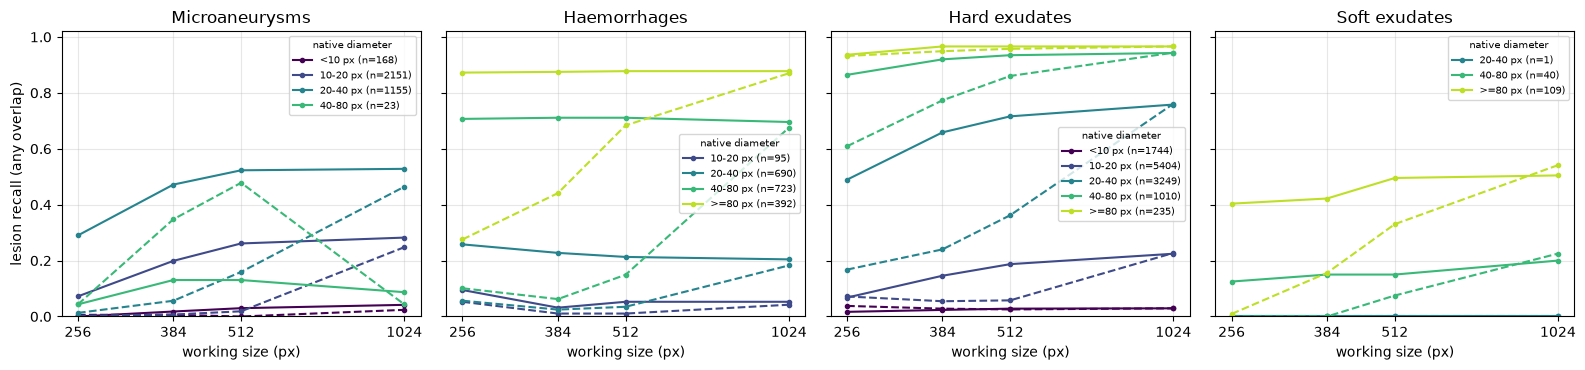

arm              rt_1024  rt_256  rt_384  rt_512  squash_256
lesion size_bin                                             
EX     <10         0.029   0.017   0.024   0.028       0.011
       10-20       0.224   0.068   0.146   0.187       0.051
       20-40       0.758   0.489   0.659   0.716       0.433
       40-80       0.943   0.864   0.920   0.935       0.843
       >=80        0.966   0.936   0.966   0.966       0.911
HE     10-20       0.053   0.095   0.032   0.053       0.074
       20-40       0.204   0.258   0.228   0.213       0.255
       40-80       0.696   0.707   0.711   0.711       0.694
       >=80        0.878   0.872   0.875   0.878       0.870
MA     <10         0.042   0.000   0.018   0.030       0.000
       10-20       0.282   0.072   0.199   0.261       0.056
       20-40       0.528   0.290   0.472   0.523       0.245
       40-80       0.087   0.043   0.130   0.130       0.043
SE     20-40       0.000   0.000   0.000   0.000       0.000
       40-80       0.200   0.125   0.150   0.150       0.125
       >=80        0.505   0.404   0.422   0.495       0.440

In [32]:
sizes = [256, 384, 512, 1024]
fig, axes = plt.subplots(1, len(TYPES), figsize=(4 * len(TYPES), 3.8), sharey=True, squeeze=False)
for ax, code in zip(axes[0], TYPES):
    for name, colour in zip(BIN_NAMES, plt.cm.viridis(np.linspace(0, 0.9, len(BIN_NAMES)))):
        for kind, ls in (("rt", "-"), ("direct", "--")):
            d = by_size[(by_size.lesion == code) & (by_size.size_bin == name)].set_index("arm")
            arms = [f"{kind}_{t}" for t in sizes if f"{kind}_{t}" in d.index]
            if arms:
                ax.plot([int(a.split("_")[1]) for a in arms], d.loc[arms, "recall"], ls, color=colour,
                        marker="o", ms=3, label=f"{name} px (n={d.n_true.iloc[0]})" if kind == "rt" else None)
    ax.set_xscale("log", base=2); ax.set_xticks(sizes); ax.set_xticklabels(sizes); ax.minorticks_off()
    ax.set_title(NAMES[code]); ax.set_xlabel("working size (px)"); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, title="native diameter", title_fontsize=7)
axes[0][0].set_ylabel("lesion recall (any overlap)")
plt.tight_layout(); fig.savefig(OUT / "recall_vs_size.png", dpi=150); plt.show()

by_size[by_size.arm.str.startswith("rt") | (by_size.arm == "squash_256")].pivot_table(
    index=["lesion", "size_bin"], columns="arm", values="recall", observed=True).round(3)

## 7. Look at the overlays

Numbers can hide silly bugs, such as masks shifted by the padding. For four images, from fewest to most microaneurysms, we show the clinicians' masks next to the tool's at 1024 and through a 256 round trip. The bottom row zooms in on one typical microaneurysm.

**Check:** do predictions sit on the lesions? Is there a consistent offset? Do predictions look blocky or spread at 256? Red dots are thickened in the full-image row only, so tiny lesions stay visible.

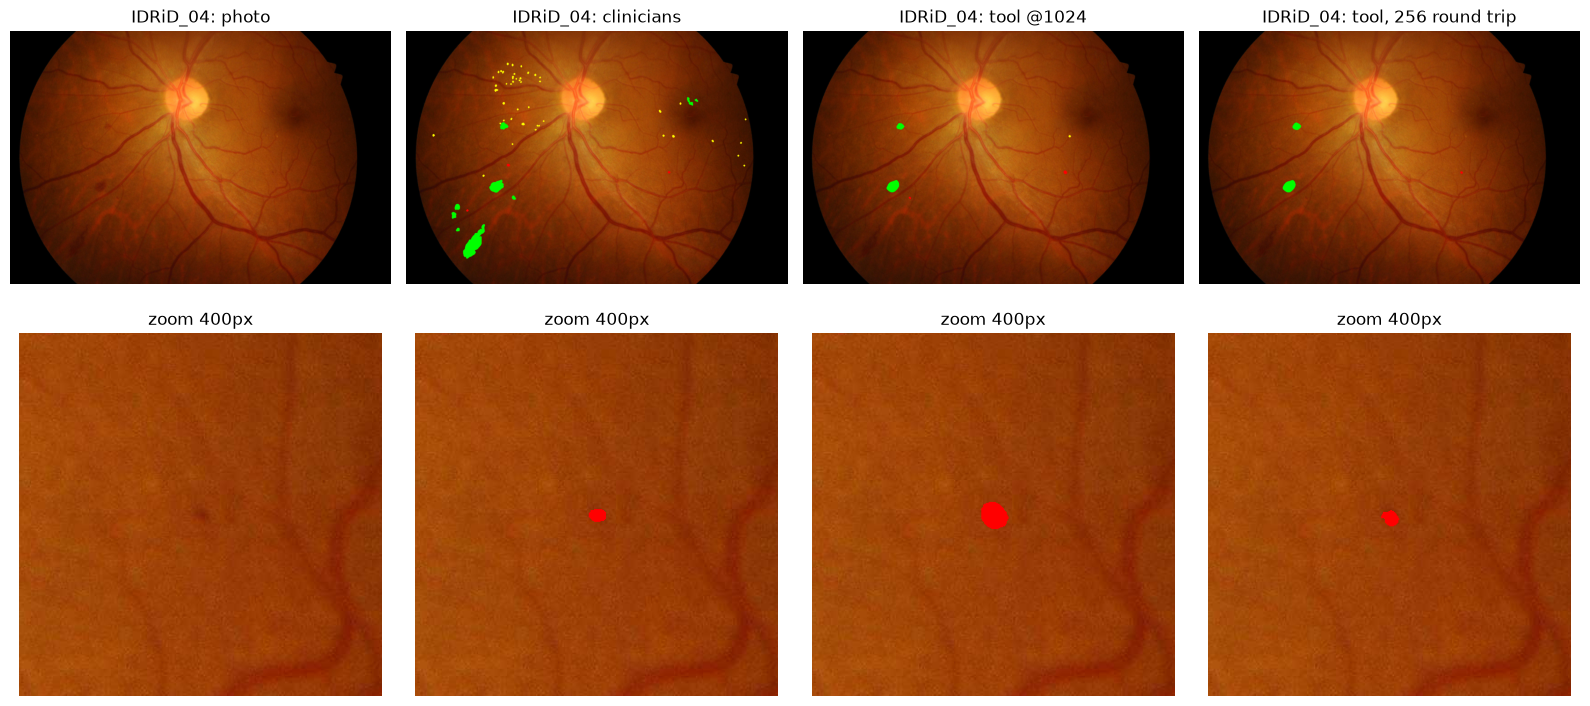

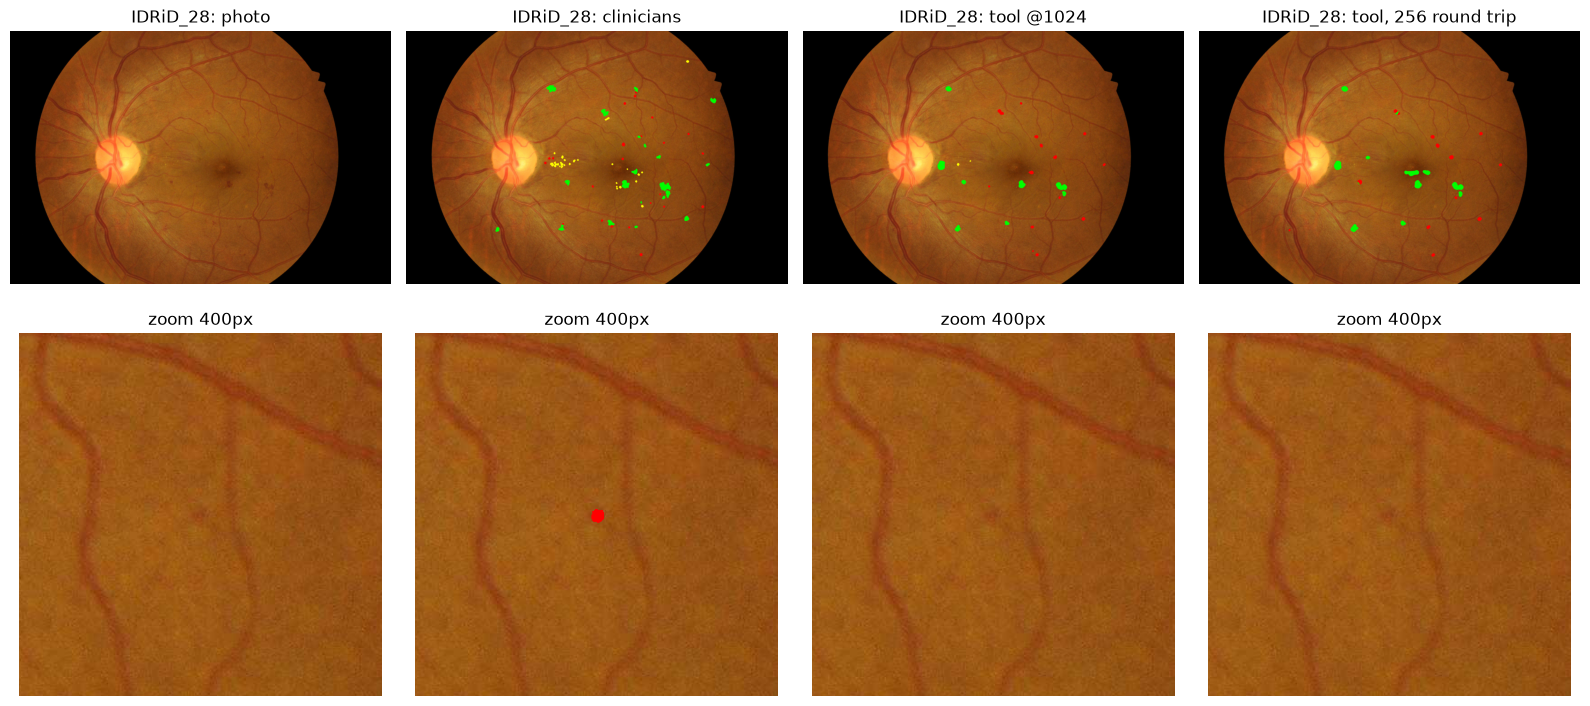

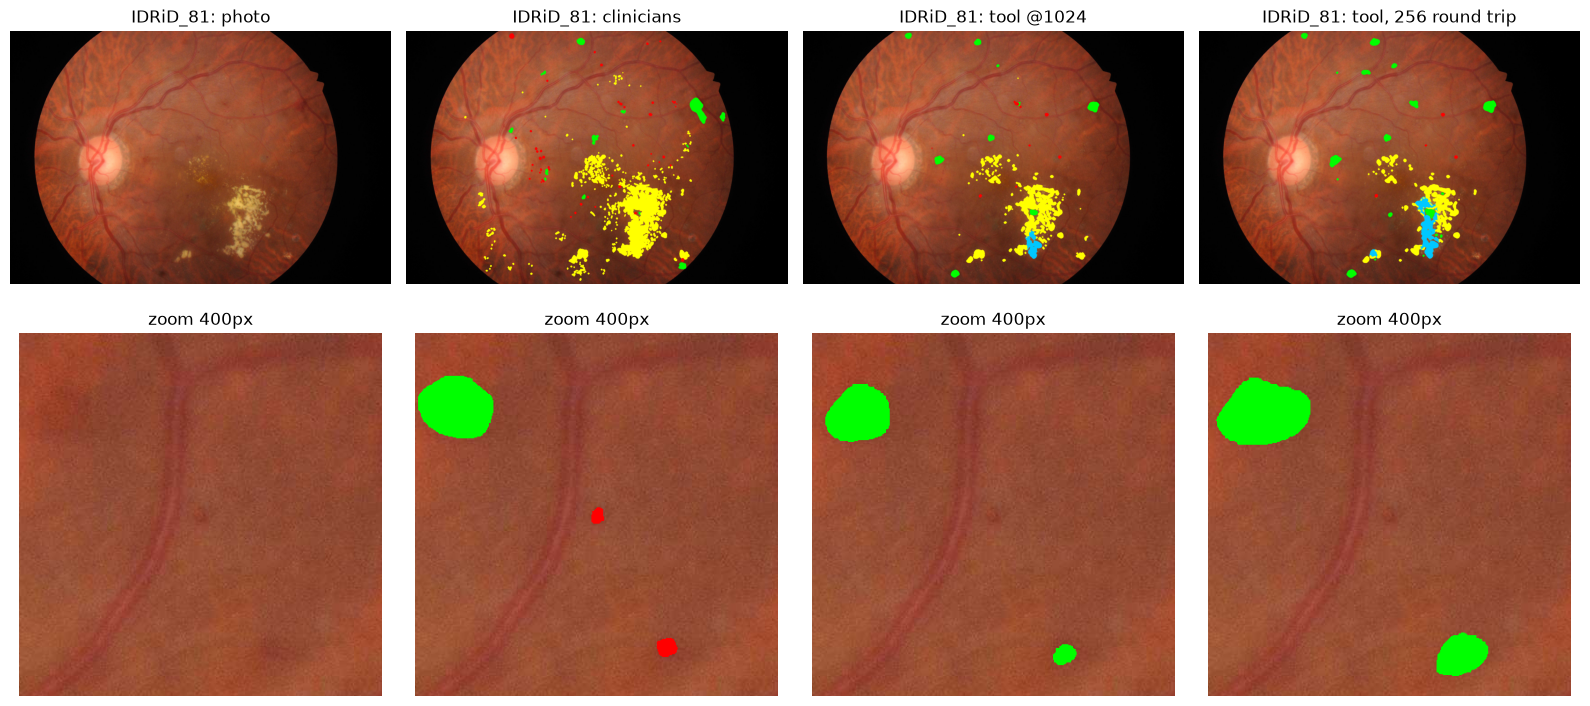

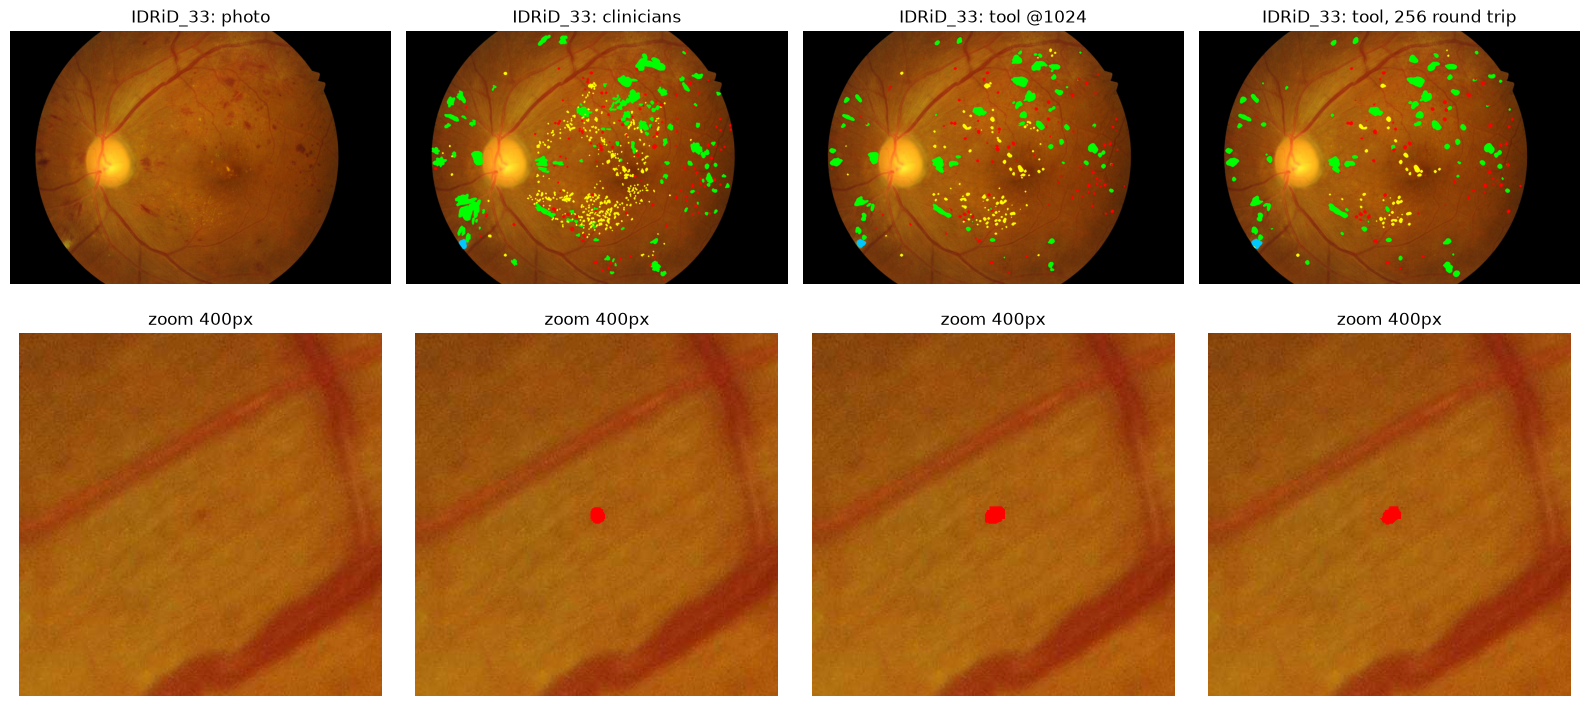

In [33]:
def paint(photo, masks_by_type, thicken=0):
    out = photo.copy()
    for code, m in masks_by_type.items():
        out[ndimage.binary_dilation(m, iterations=thicken) if thicken else m] = COLOURS[code]
    return out


counts = per_image[(per_image.arm == ORDER[0]) & (per_image.lesion == "MA")].sort_values("n_true")
picks = counts.image_id.iloc[np.linspace(0, len(counts) - 1, min(4, len(counts))).round().astype(int)].unique()
PANELS = [("direct_1024", "tool @1024"), ("rt_256", "tool, 256 round trip")]

for image_id in picks:
    photo = np.array(Image.open(images[image_id]).convert("RGB"))
    truth = {code: load_mask(p) for code, p in masks[image_id].items()}
    preds = {arm: {c: np.array(Image.open(OUT / "preds" / arm / f"{image_id}.png")) == l for c, l in LABELS.items()} for arm, _ in PANELS}

    # zoom on the microaneurysm closest to the median size in this image
    lab, n = ndimage.label(truth["MA"], structure=EIGHT)
    areas = np.bincount(lab.ravel())[1:]
    comp = int(np.argmin(np.abs(areas - np.median(areas)))) + 1
    cy, cx = [int(v) for v in ndimage.center_of_mass(lab == comp)]
    win = 200
    y0, x0 = np.clip(cy - win, 0, photo.shape[0] - 2 * win), np.clip(cx - win, 0, photo.shape[1] - 2 * win)
    box = (slice(y0, y0 + 2 * win), slice(x0, x0 + 2 * win))

    fig, ax = plt.subplots(2, 4, figsize=(16, 7.5))
    views = [("photo", {}), ("clinicians", truth)] + [(title, preds[arm]) for arm, title in PANELS]
    for i, (title, m) in enumerate(views):
        ax[0, i].imshow(paint(photo, m, thicken=6) if m else photo); ax[0, i].set_title(f"{image_id}: {title}")
        ax[1, i].imshow(paint(photo[box], {c: v[box] for c, v in m.items()}) if m else photo[box])
        ax[1, i].set_title(f"zoom {2 * win}px")
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout(); fig.savefig(OUT / f"overlay_{image_id}.png", dpi=110); plt.show()

## 8. Choosing the training size

**Current numbers for the decision**

| Working size | Pixels vs 256 | Native px per working px | Step 1: MAs at least 2 px wide |
|---|---|---|---|
| 256 | 1× | 16.8 | 2.3% |
| 384 | 2.25× | 11.2 | 23.2% |
| 512 | 4× | 8.4 | 53.3% |
| 1024 | 16× | 4.2 | 98.6% |

**Rule for the decision (fixed now, so the result can't bend it):** choose the **smallest size whose `rt` microaneurysm recall is within 5 percentage points of `rt_1024`**, with precision and Dice not clearly worse. Then:

- Nothing below 1024 qualifies → restore at 1024
- A smaller size qualifies → restore at that size, and spend the saved compute elsewhere
- `direct_1536` beats `direct_1024` by a clear margin for MAs → 1024 isn't the ceiling, so test 1536 or 2048 before deciding

**Limits to keep in mind**
- The segmenter is the measuring tool, so its recall is a **lower bound** on what is visible. A lesion it misses at 1024 isn't proof the lesion is gone; `rt_1024` recall is the ceiling for this tool, and the comparison between sizes is what matters.
- IDRiD photos are **4288 × 2848**, and retinas nearly fill the width, so cropping the black borders gains only a few percent.

**Working size is not training window.** Working size sets how many pixels a lesion gets. The training window only sets how much of the image the network sees per step. So 1024 doesn't automatically mean 16× the training cost: a convolutional restorer can train on 256 px patches cut from images at the working size, then restore whole images at the larger size ("train small, restore big"). Before relying on this, check each restorer. `_SwinUNetSlim` has fixed-size windows, and `_PathUNet` has self-attention at the bottleneck, so their behaviour may change between patch size and full size.

## 9. What to send back, and what to log

Send Claude:
1. the sanity checks from section 4
2. `summary_by_type.csv`, `recall_by_size.csv` and `recall_vs_size.png`
3. the overlays, plus one sentence on what you see

**Log line for your `til` RQ1 log:**
`YYYY-MM-DD · Step 2 · toolkit DDR weights (commit ____) on IDRiD · MA recall rt_256 = __, rt_512 = __, rt_1024 = __ · squash_256 = __ · decision: ____`